<a href="https://colab.research.google.com/github/Arceus2006/AIML-project/blob/main/Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Train shape: (1460, 81)
Test shape: (1459, 80)

First 5 rows:
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSo

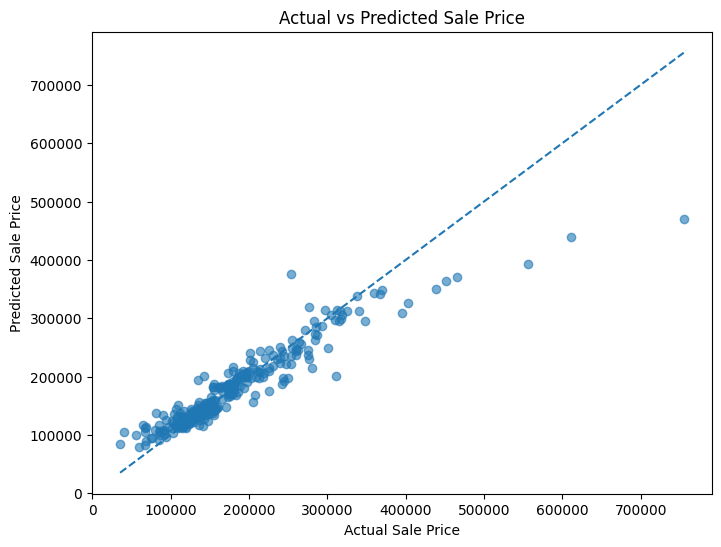


Training final model on complete dataset...
Final model trained!

First 10 test predictions:
[126715.044 152579.394 184835.062 190473.834 194552.688 183049.858
 173043.42  177116.038 181911.578 131722.436]

Submission file created:
random_forest_submission.csv

Submission preview:
     Id   SalePrice
0  1461  126715.044
1  1462  152579.394
2  1463  184835.062
3  1464  190473.834
4  1465  194552.688


In [ ]:
# ============================================================
# RANDOM FOREST REGRESSION - HOUSE PRICE PREDICTION
# ============================================================

# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import matplotlib.pyplot as plt


# ============================================================
# 2. LOAD DATA
# ============================================================

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

print("\nFirst 5 rows:")
print(train.head())


# ============================================================
# 3. SEPARATE FEATURES AND TARGET
# ============================================================

X = train.drop("SalePrice", axis=1)
y = train["SalePrice"]

# Keep test IDs for final submission
test_ids = test["Id"]

print("\nFeatures:", X.shape)
print("Target:", y.shape)


# ============================================================
# 4. CHECK MISSING VALUES
# ============================================================

missing_values = train.isnull().sum()

missing_values = missing_values[
    missing_values > 0
].sort_values(ascending=False)

print("\nColumns with missing values:")
print(missing_values)


# ============================================================
# 5. IDENTIFY NUMERICAL AND CATEGORICAL COLUMNS
# ============================================================

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("\nNumber of numerical features:",
      len(numerical_features))

print("Number of categorical features:",
      len(categorical_features))


# ============================================================
# 6. TRAIN-VALIDATION SPLIT
# ============================================================

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])


# ============================================================
# 7. DATA PREPROCESSING
# ============================================================

# Numerical preprocessing
# Missing numerical values -> median
numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])


# Categorical preprocessing
# Missing categorical values -> most frequent value
# Categorical values -> One Hot Encoding
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])


# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline,
        numerical_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])


# ============================================================
# 8. RANDOM FOREST REGRESSION MODEL
# ============================================================

random_forest = RandomForestRegressor(
    n_estimators=500,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)


# ============================================================
# 9. CREATE COMPLETE PIPELINE
# ============================================================

model = Pipeline([
    (
        "preprocessing",
        preprocessor
    ),
    (
        "random_forest",
        random_forest
    )
])


# ============================================================
# 10. TRAIN MODEL
# ============================================================

print("\nTraining Random Forest...")

model.fit(
    X_train,
    y_train
)

print("Training completed!")


# ============================================================
# 11. MAKE VALIDATION PREDICTIONS
# ============================================================

y_pred = model.predict(X_val)


# ============================================================
# 12. MODEL EVALUATION
# ============================================================

mae = mean_absolute_error(
    y_val,
    y_pred
)

mse = mean_squared_error(
    y_val,
    y_pred
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_val,
    y_pred
)

print("\n================================")
print("MODEL PERFORMANCE")
print("================================")

print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R²   :", r2)


# ============================================================
# 13. ACTUAL VS PREDICTED VALUES
# ============================================================

results = pd.DataFrame({
    "Actual": y_val.values,
    "Predicted": y_pred
})

print("\nActual vs Predicted:")
print(results.head(10))


# ============================================================
# 14. ACTUAL VS PREDICTED PLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val,
    y_pred,
    alpha=0.6
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted Sale Price")

# Perfect prediction line
min_value = min(y_val.min(), y_pred.min())
max_value = max(y_val.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.show()


# ============================================================
# 15. TRAIN FINAL MODEL ON COMPLETE TRAINING DATA
# ============================================================

print("\nTraining final model on complete dataset...")

model.fit(
    X,
    y
)

print("Final model trained!")


# ============================================================
# 16. PREDICT TEST DATA
# ============================================================

test_predictions = model.predict(test)

print("\nFirst 10 test predictions:")

print(test_predictions[:10])


# ============================================================
# 17. CREATE SUBMISSION FILE
# ============================================================

submission = pd.DataFrame({
    "Id": test_ids,
    "SalePrice": test_predictions
})


# Make sure column order matches sample submission
submission = submission[
    sample_submission.columns
]


# ============================================================
# 18. SAVE SUBMISSION
# ============================================================

submission.to_csv(
    "random_forest_submission.csv",
    index=False
)

print("\nSubmission file created:")
print("random_forest_submission.csv")

print("\nSubmission preview:")
print(submission.head())

In [ ]:
# ============================================
# RANDOM FOREST CLASSIFICATION
# HOUSE PRICE DATASET
# ============================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)


# ============================================
# 1. LOAD DATA
# ============================================

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

print("\nFirst 5 rows:")
print(train.head())


# ============================================
# 2. CREATE CLASS LABELS
# ============================================

def price_category(price):

    if price < 150000:
        return "Low"

    elif price < 300000:
        return "Medium"

    else:
        return "High"


train["PriceCategory"] = train["SalePrice"].apply(
    price_category
)


print("\nPrice category distribution:")
print(train["PriceCategory"].value_counts())


# ============================================
# 3. DEFINE FEATURES AND TARGET
# ============================================

X = train.drop(
    ["SalePrice", "PriceCategory"],
    axis=1
)

y = train["PriceCategory"]


# ============================================
# 4. IDENTIFY COLUMN TYPES
# ============================================

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns


print("\nNumber of numerical features:",
      len(numerical_features))

print("Number of categorical features:",
      len(categorical_features))


# ============================================
# 5. TRAIN-TEST SPLIT
# ============================================

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


print("\nTraining samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])


# ============================================
# 6. NUMERICAL PREPROCESSING
# ============================================

numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])


# ============================================
# 7. CATEGORICAL PREPROCESSING
# ============================================

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),

    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])


# ============================================
# 8. COMBINE PREPROCESSING
# ============================================

preprocessor = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline,
        numerical_features
    ),

    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])


# ============================================
# 9. RANDOM FOREST CLASSIFIER
# ============================================

classifier = RandomForestClassifier(
    n_estimators=200,
    criterion="gini",
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)


# ============================================
# 10. COMPLETE PIPELINE
# ============================================

model = Pipeline([
    (
        "preprocessing",
        preprocessor
    ),

    (
        "classifier",
        classifier
    )
])


# ============================================
# 11. TRAIN MODEL
# ============================================

print("\nTraining Random Forest Classifier...")

model.fit(
    X_train,
    y_train
)

print("Training completed!")


# ============================================
# 12. MAKE PREDICTIONS
# ============================================

y_pred = model.predict(X_val)


# ============================================
# 13. ACCURACY
# ============================================

accuracy = accuracy_score(
    y_val,
    y_pred
)

print("\n================================")
print("MODEL PERFORMANCE")
print("================================")

print("Accuracy:", accuracy)


# ============================================
# 14. CLASSIFICATION REPORT
# ============================================

print("\nClassification Report:")

print(
    classification_report(
        y_val,
        y_pred
    )
)


# ============================================
# 15. CONFUSION MATRIX
# ============================================

print("\nConfusion Matrix:")

cm = confusion_matrix(
    y_val,
    y_pred
)

print(cm)


# ============================================
# 16. SAMPLE PREDICTIONS
# ============================================

results = pd.DataFrame({
    "Actual": y_val.values,
    "Predicted": y_pred
})

print("\nActual vs Predicted:")
print(results.head(20))

Train shape: (1460, 81)
Test shape: (1459, 80)

First 5 rows:
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSo